#### Multi-Armed Bandits (MAB) & Exploration-Exploitation

In a Multi-Armed Bandit problem, there is no state transition ($s_{t+1}$ does not depend on $a_t$), the agent repeatedly selects one of $K$ arms to maximize cumulative reward or minimize regret.

Regret is defined as $\text{regret}_t = \mu^* - r_t, \text{where } \mu^* = \max_{k \in \{0,\dots,K-1\}} \mu_k$.

- Expected regret $\mathbb{E}[\mu^* - r_t] = \mu^* - \mu_{a_t} \ge 0$ is always non-negative when evaluated against true expected payoffs.

- Realized (or sample) regret in a single simulation run can be negative if a sampled payoff $r_t \sim {N}(\mu^*, \sigma^2)$ happens to exceed the mean $\mu^*$ (for instance, sampling $> 10$ from Arm 2 where $\mu_2 = 10, \sigma_2 = 0.7$). Over num_trials = 100, an average regret of -0.0474 for exploit_greedy() simply reflects positive random noise around $\mu_2 = 10$.

#### Strategy Trade-offs in the Code

- Explore-Only: Selects arms uniformly at random ($\frac{1}{K}$). High variance and high cumulative regret because it never concentrates pulls on the optimal arm ($\mu_2 = 10$).

- Greedy Exploitation: Always picks $\arg\max_k \mu_k$. exploit_greedy and epsilon_greedy read the true distribution means payoff_params[k]['mu'] directly rather than maintaining empirical sample estimates $\hat{\mu}_k$ learned from observed rewards. In a real bandit where $\mu_k$ is unknown, greedy exploitation without initial sampling can lock onto a suboptimal arm if early samples are noisy.

- $\epsilon$-Greedy: Balances exploitation with a constant probability $\epsilon$ of uniform random exploration. Because $\epsilon$ is fixed (0.1), it continues paying an exploration cost even after the optimal arm is clear (decaying $\epsilon_t$ is often used to reduce asymptotic regret).

- Upper Confidence Bound — UCB1 (ucb): Applies optimism in the face of uncertainty: $\text{UCB}_i(t) = \hat{\mu}_i(t) + c \sqrt{\frac{\ln t}{N_i(t)}}$. Arms with lower empirical counts $N_i(t)$ receive a larger uncertainty bonus, so exploration naturally targets under-sampled arms rather than choosing randomly.

#### Solve MAB using different stategies

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

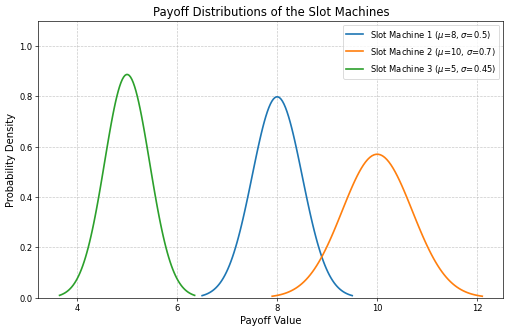

In [ ]:
'''
Define payoff distributions of three slot machines (Multi-Armed Bandit Arms).
Thhe density function (PDFs) of K=3 slot machines with normal payoff distributions to allow comparison.
'''

# Number of slot machines (arms)
K = 3

# Payoff distributions params (mean and standard deviation) for each slot
payoff_params = [
    {'mu': 8, 'sigma': 0.5},
    {'mu': 10, 'sigma': 0.7},
    {'mu': 5, 'sigma': 0.45}
]

# Plot payoff distributions
plt.figure(figsize=(10, 6), dpi=60)

for slot_machine in range(K):
    mu = payoff_params[slot_machine]['mu']
    sigma = payoff_params[slot_machine]['sigma']

    # Generate 100 evenly spaced points over 3 stds around the mean
    x = np.linspace(mu - 3 * sigma, mu + 3 * sigma, 100)
    # Normal distribution probability density function
    y = 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-(x - mu)**2 / (2 * sigma**2))

    plt.plot(x, y, label=f'Slot Machine {slot_machine+1} ($\\mu$={mu}, $\\sigma$={sigma})', linewidth=2)

plt.title('Payoff Distributions of the Slot Machines', fontsize=14)
plt.xlabel('Payoff Value', fontsize=12)
plt.ylabel('Probability Density', fontsize=12)
plt.ylim(0, 1.1)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='upper right', fontsize=10)
plt.show()

In [ ]:
'''
Configuration and environment setup for the Multi-Armed Bandit (MAB) simulation.
Defines simulation trials, the payoff sampling process, and the optimal reward benchmark.
'''

# Total number of iterations/trials in the simulation
num_trials = 100

# Maximum possible expected reward across all arms (for regret calculation)
max_reward = max(payoff_params[slot_machine]['mu'] for slot_machine in range(K))

def sample_payoff(slot_machine: int) -> float:
    """
    Samples a random payoff from a given slot machine's normal distribution.

    Parameters:
        slot_machine (int): The index of the chosen slot machine arm (0 to K-1).
    Returns:
        float: A randomly sampled reward from N(mu, sigma^2).
    """
    mu = payoff_params[slot_machine]['mu']
    sigma = payoff_params[slot_machine]['sigma']
    return float(np.random.normal(mu, sigma))

#### Explore only Strategy (1)

In [ ]:
def explore_only() -> float:
    """
    Implements the Pure Exploration (random selection) strategy for the Multi-Armed Bandit. Each trial chooses an arm entirely at random, providing a baseline for regret comparison.

    Returns:
        float: The average regret accumulated over all simulation trials.
    """
    total_regret = 0.0
    for _ in range(num_trials):
        # Randomly select any of the K available slot machines
        selected_machine = int(np.random.randint(K))
        reward = sample_payoff(selected_machine)

        # Regret is the difference between optimal expected reward and actual received reward
        regret = max_reward - reward
        total_regret += regret

    avg_regret = total_regret / num_trials
    return float(avg_regret)

#### Exploit Greedy Strategy (2)

In [ ]:
def exploit_greedy() -> float:
    """
    Implements the Pure Exploitation (greedy selection) strategy for the Multi-Armed Bandit. Each trial chooses the arm that currently yields the maximum expected payoff based on prior parameters, demonstrating a zero-exploration strategy.

    Returns:
        float: The average regret accumulated over all simulation trials.
    """
    total_regret = 0.0
    # Always pick the arm with the highest expected true mean (mu)
    selected_machine = int(np.argmax([payoff_params[slot_machine]['mu'] for slot_machine in range(K)]))

    for _ in range(num_trials):
        reward = sample_payoff(selected_machine)
        regret = max_reward - reward
        total_regret += regret

    avg_regret = total_regret / num_trials
    return float(avg_regret)

#### $\epsilon$ Greedy Strategy (3)

In [ ]:
def epsilon_greedy(epsilon: float) -> float:
    """
    Implements the Epsilon-Greedy strategy for the Multi-Armed Bandit.
    With probability epsilon, the agent explores a random arm; otherwise,
    it exploits the best-performing arm based on true expected payoff means.

    Parameters:
        epsilon (float): Exploration probability param (typically in [0, 1]).
    Returns:
        float: The average regret accumulated over all simulation trials.
    """
    total_regret = 0.0
    for _ in range(num_trials):
        if np.random.rand() < epsilon:
            # Exploration step: pick an arm at random
            selected_machine = int(np.random.randint(K))
        else:
            # Exploitation step: pick the best-known arm
            selected_machine = int(np.argmax([payoff_params[slot_machine]['mu'] for slot_machine in range(K)]))

        reward = sample_payoff(selected_machine)
        regret = max_reward - reward
        total_regret += regret

    avg_regret = total_regret / num_trials
    return float(avg_regret)

#### Upper Confidence Bound (UCB) strategy

In [ ]:
def ucb(c: float) -> float:
    """
    Implements the Upper Confidence Bound (UCB1) strategy for the Multi-Armed Bandit. The algorithm selects arms based on an optimism-in-the-face-of-uncertainty estimate, which accounts for both the estimated mean reward and the uncertainty of that estimate.

    Parameters:
        c (float): Exploration constant controlling the degree of uncertainty exploration.
    Returns:
        float: The average regret accumulated over all simulation trials.
    """
    num_plays = np.zeros(K)
    sum_rewards = np.zeros(K)
    total_regret = 0.0

    # Play each slot machine once to initialize estimates
    for i in range(K):
        reward = sample_payoff(i)
        num_plays[i] += 1
        sum_rewards[i] += reward

    # Continue playing using the Upper Confidence Bound selection strategy
    for t in range(K, num_trials):
        # UCB values using the formula: Mean + c * sqrt(ln(t) / N_i(t))
        ucb_values = sum_rewards / num_plays + c * np.sqrt(np.log(t) / num_plays)
        selected_machine = int(np.argmax(ucb_values))

        reward = sample_payoff(selected_machine)
        num_plays[selected_machine] += 1
        sum_rewards[selected_machine] += reward

        # Regret is calculated using the expected optimal value (max_reward)
        total_regret += max_reward - reward

    avg_regret = total_regret / num_trials
    return float(avg_regret)

#### Run strategies and compute average regrets

In [ ]:
avg_regret_explore = explore_only()
avg_regret_greedy = exploit_greedy()
avg_regret_epsilon_greedy = epsilon_greedy(0.1)
avg_regret_ucb = ucb(2)

print(
f'Average Regret for Explore-Only Strategy: {round(avg_regret_explore, 4)}')
print(
f'Average Regret for Exploit-Greedy Strategy: {round(avg_regret_greedy, 4)}')
print(f'Average Regret for Epsilon-Greedy Strategy: {round(avg_regret_epsilon_greedy, 4)}')
print(f'Average Regret for UCB Strategy: {round(avg_regret_ucb, 4)}')

Average Regret for Explore-Only Strategy: 2.5123
Average Regret for Exploit-Greedy Strategy: -0.0474
Average Regret for Epsilon-Greedy Strategy: 0.1612
Average Regret for UCB Strategy: 0.1117


### Advantage Actor-Critic (A2C) on CartPole-v1


Actor-Critic methods pair a policy network (Actor) $\pi_\theta(a \mid s)$ with a value function network (Critic) $V_\phi(s)$

- Actor outputs action probabilities (via Categorical(action_probs)) and is updated using policy gradients scaled by how much better an action was than expected.

- Critic estimates expected return $V_\phi(s)$ from state $s$, acting both as a variance reducing baseline and as a bootstrap target for future rewards.


Advantage Estimation: 1-Step TD vs. $N$-Step / Monte Carlo Return

Two common ways to form the advantage signal

- First A2C loop (1-step TD advantage):
$\delta_t = r_t + \gamma (1 - \text{done}_t) V_\phi(s_{t+1}) - V_\phi(s_t)$.
Updates parameters online at every step using bootstrapped next-state values.

- train_a2c (v2 — episode return / reward-to-go baseline):  
Computes discounted returns backward from the end of the episode:
$G_t = r_t + \gamma \, \text{mask}_t \, G_{t+1}$, and sets $A_t = G_t - V_\phi(s_t)$
training the critic with MSE loss ${L}_{\text{critic}} = \text{MSE}(V_\phi(s_t), G_t)$ and the actor with $-\mathbb{E}[\log \pi_\theta(a_t \mid s_t) \, \text{detach}(A_t)]$. This lowers variance compared to unbaselined REINFORCE while using full-episode rollouts rather than 1-step bootstrapping.

In [ ]:
# the classic control environment libraries (gym)
!pip install gym[classic_control] > /dev/null 2>&1
!pip install torch > /dev/null 2>&1

In [ ]:
import gym
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

#### Actor network

A2C, RL algorithm combining elements from policy gradient methods like Reinforce and value-based methods like Q-learning. A2C algorithm aims to learn an optimal policy by iteratively improving the actor and critic networks.

In [ ]:
class Actor(nn.Module):
    """
    Actor network of the Advantage Actor-Critic (A2C) model.
    Maps state inputs to a probability distribution over discrete actions.
    """
    def __init__(self, state_dim: int, action_dim: int):
        """
        Parameters:
            state_dim (int): Dimensionality of the state observation space.
            action_dim (int): Number of discrete actions available to the agent.
        """
        super(Actor, self).__init__()
        self.fc1 = nn.Linear(state_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, action_dim)

    def forward(self, state: torch.Tensor) -> torch.Tensor:
        """
        Performs a forward pass to compute the action selection probabilities.

        Parameters:
            state (torch.Tensor): Current environment state tensor.
        Returns:
            torch.Tensor: Probability distribution over the action space.
        """
        x1 = F.relu(self.fc1(state))
        x2 = F.relu(self.fc2(x1))
        action_probs = F.softmax(self.fc3(x2), dim=-1)
        return action_probs

#### Critic Network

In [ ]:
class Critic(nn.Module):
    """
    Critic network of the Advantage Actor-Critic (A2C) model. Maps state inputs to a single scalar value representing the state's expected return.
    """
    def __init__(self, state_dim: int):
        """
        Parameters:
            state_dim (int): Dimensionality of the state observation space.
        """
        super(Critic, self).__init__()
        self.fc1 = nn.Linear(state_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)

    def forward(self, state: torch.Tensor) -> torch.Tensor:
        """
        Performs a forward pass to compute the state-value estimate V(s).

        Parameters:
            state (torch.Tensor): Current environment state tensor.
        Returns:
            torch.Tensor: Evaluated scalar state value prediction.
        """
        x1 = F.relu(self.fc1(state))
        x2 = F.relu(self.fc2(x1))
        value = self.fc3(x2)
        return value

#### CartPole-v1 environment

In [ ]:
# Initialize the standard Gym environment and extract dimensions
env = gym.make('CartPole-v1')
env.seed(0)

# Explicitly capture observation and action spaces dimensions with proper typing
state_dim: int = env.observation_space.shape[0]
action_dim: int = env.action_space.n

#### Configure A2C

In [ ]:
# Instantiate actor and critic network modules
actor: Actor = Actor(state_dim, action_dim)
critic: Critic = Critic(state_dim)

# Configure distinct optimizers for both policy and value networks
adam_actor: optim.Optimizer = torch.optim.Adam(actor.parameters(), lr=3e-3)
adam_critic: optim.Optimizer = torch.optim.Adam(critic.parameters(), lr=1e-3)

# Define discount factor for expected rewards
gamma: float = 0.99

#### A2C Training

In [ ]:
from typing import Dict, List, Any

# Fix Gym compatibility issue with NumPy 2.x
if not hasattr(np, 'bool8'):
    np.bool8 = np.bool_

# Configure training parameters
num_episodes: int = 500
episode_rewards: List[float] = []

# Dictionary to record losses and returns over iterations
stats: Dict[str, List[Any]] = {
    'actor loss': [],
    'critic loss': [],
    'return': []
}

# Initialize tqdm progress tracking bar
pbar = tqdm(total=num_episodes, desc="Training A2C")

for episode in range(num_episodes):
    done: bool = False
    total_reward: float = 0.0
    state: np.ndarray = env.reset()
    env.seed(0)

    # Temporary variables to store loss objects for logging per episode
    last_actor_loss: torch.Tensor = torch.tensor(0.0)
    last_critic_loss: torch.Tensor = torch.tensor(0.0)

    while not done:
        # Feed state observation into the Actor network to sample an action
        probs: torch.Tensor = actor(torch.FloatTensor(state))
        dist = Categorical(probs)
        action = dist.sample()

        # Take action in environment and collect outcomes
        next_state, reward, done, _ = env.step(action.detach().data.numpy())

        # Calculate Critic's temporal difference advantage
        state_val = critic(torch.FloatTensor(state))
        next_state_val = critic(torch.FloatTensor(next_state))
        advantage: torch.Tensor = reward + (1.0 - float(done)) * gamma * next_state_val - state_val

        total_reward += float(reward)
        state = next_state

        # Compute value loss and optimize Critic parameters
        critic_loss: torch.Tensor = advantage.pow(2).mean()
        adam_critic.zero_grad()
        critic_loss.backward()
        adam_critic.step()

        # Compute policy objective and optimize Actor parameters
        actor_loss: torch.Tensor = -dist.log_prob(action) * advantage.detach()
        adam_actor.zero_grad()
        actor_loss.backward()
        adam_actor.step()

        # Store latest scalar updates
        last_actor_loss = actor_loss
        last_critic_loss = critic_loss

    episode_rewards.append(total_reward)
    stats['actor loss'].append(last_actor_loss)
    stats['critic loss'].append(last_critic_loss)
    stats['return'].append(total_reward)

    # Update progress metrics periodically or on task steps
    pbar.set_description(f"Episode {episode+1}")
    pbar.set_postfix({
        'Actor Loss': f"{last_actor_loss.item():.4f}",
        'Critic Loss': f"{last_critic_loss.item():.4f}",
        'Reward': total_reward
    })
    pbar.update(1)

pbar.close()

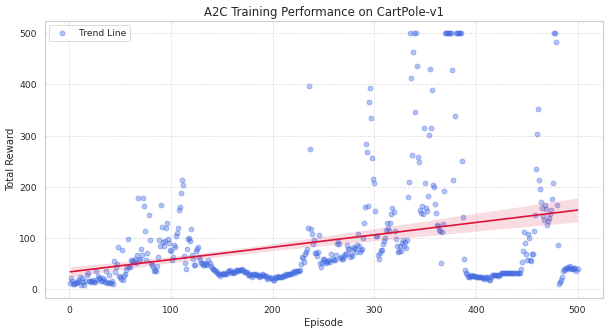

In [ ]:
# Prepare a DataFrame containing episode outcomes for structured plotting
data: pd.DataFrame = pd.DataFrame({
    'Episode': range(1, num_episodes + 1),
    'Reward': episode_rewards
})

# Configure figure size and DPI for high-quality visualization
plt.figure(figsize=(12, 6), dpi=60)
sns.set_theme(style='whitegrid')

# Plot a regression/trend line indicating agent improvement
sns.regplot(
    data=data,
    x='Episode',
    y='Reward',
    scatter_kws={'alpha': 0.4, 'color': 'royalblue'},
    line_kws={'color': 'crimson', 'linewidth': 2},
    label='Trend Line'
)

plt.title('A2C Training Performance on CartPole-v1', fontsize=14)
plt.xlabel('Episode', fontsize=12)
plt.ylabel('Total Reward', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

#### A2C Training Loop Implementation (v2)

In [ ]:
from typing import List

def train_a2c(
    env: gym.Env,
    actor: nn.Module,
    critic: nn.Module,
    num_episodes: int = 500,
    lr_actor: float = 3e-4,
    lr_critic: float = 1e-3,
    gamma: float = 0.99
) -> List[float]:
    """
    Trains the Actor and Critic networks on the provided Gym environment
    using a multi-step temporal difference actor-critic trajectory batch update.

    Parameters:
        env (gym.Env): The target reinforcement learning environment.
        actor (nn.Module): Policy network predicting action probabilities.
        critic (nn.Module): Value network predicting state values.
        num_episodes (int): Total number of training episodes.
        lr_actor (float): Learning rate for the Actor optimizer.
        lr_critic (float): Learning rate for the Critic optimizer.
        gamma (float): Discount factor for future rewards.

    Returns:
        List[float]: Collected total rewards per episode over the course of training.
    """
    actor_optimizer = optim.Adam(actor.parameters(), lr=lr_actor)
    critic_optimizer = optim.Adam(critic.parameters(), lr=lr_critic)

    episode_rewards: List[float] = []

    for episode in tqdm(range(num_episodes), desc="Training A2C (v2)"):
        state = env.reset()
        done: bool = False
        episode_reward: float = 0.0

        log_probs: List[torch.Tensor] = []
        values: List[torch.Tensor] = []
        rewards: List[float] = []
        masks: List[float] = []

        # Rollout trajectories to collect transitions
        while not done:
            state_t = torch.FloatTensor(state).unsqueeze(0)
            action_probs = actor(state_t)
            dist = Categorical(action_probs)
            action = dist.sample()

            next_state, reward, done, _ = env.step(action.item())

            log_prob = dist.log_prob(action)
            value = critic(state_t)

            log_probs.append(log_prob)
            values.append(value)
            rewards.append(float(reward))
            masks.append(1.0 - float(done))

            state = next_state
            episode_reward += float(reward)

        # Compute N-step returns and corresponding advantage values
        next_state_t = torch.FloatTensor(next_state).unsqueeze(0)
        next_value = critic(next_state_t)

        returns: List[float] = []
        R: float = float(next_value.item()) if not done else 0.0
        for r, mask in zip(reversed(rewards), reversed(masks)):
            R = r + gamma * R * mask
            returns.insert(0, R)

        returns_tensor = torch.FloatTensor(returns)
        values_tensor = torch.cat(values).squeeze()
        log_probs_tensor = torch.cat(log_probs)

        # Standard Advantage calculation: A(s, a) = G_t - V(s)
        advantages = returns_tensor - values_tensor

        # Calculate joint policy (Actor) loss and baseline value (Critic) loss
        actor_loss = -(log_probs_tensor * advantages.detach()).mean()
        critic_loss = F.mse_loss(values_tensor, returns_tensor)

        # Backpropagate Actor updates
        actor_optimizer.zero_grad()
        actor_loss.backward()
        actor_optimizer.step()

        # Backpropagate Critic updates
        critic_optimizer.zero_grad()
        critic_loss.backward()
        critic_optimizer.step()

        episode_rewards.append(episode_reward)

    return episode_rewards

#### Run Training and Plot Results

In [ ]:
# Fix NumPy 2.x compatibility issues with older OpenAI gym versions
if not hasattr(np, 'bool8'):
    np.bool8 = np.bool_

# Instantiate fresh Actor and Critic networks for training
actor_v2: Actor = Actor(state_dim, action_dim)
critic_v2: Critic = Critic(state_dim)

# Execute batched training loop for the defined number of episodes
rewards: List[float] = train_a2c(env, actor_v2, critic_v2, num_episodes=500)

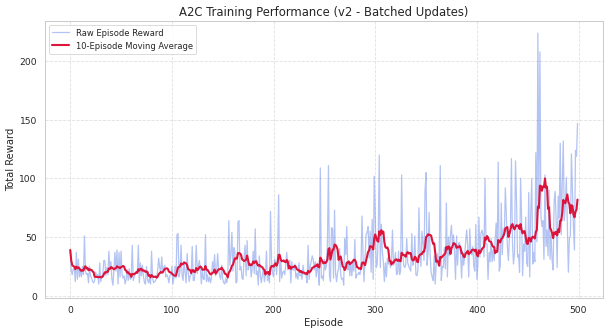

In [ ]:
# Configure canvas and style parameters
plt.figure(figsize=(12, 6), dpi=60)
sns.set_theme(style='whitegrid')

# Plot raw episode rewards along with a smoothed rolling average
plt.plot(rewards, label='Raw Episode Reward', color='royalblue', alpha=0.4)
smoothed_rewards: pd.Series = pd.Series(rewards).rolling(window=10, min_periods=1).mean()
plt.plot(smoothed_rewards, label='10-Episode Moving Average', color='crimson', linewidth=2.5)

plt.title('A2C Training Performance (v2 - Batched Updates)', fontsize=14)
plt.xlabel('Episode', fontsize=12)
plt.ylabel('Total Reward', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

#### Test the trained agent

In [ ]:
# Evaluate the performance of the trained Actor network on a single trial run
state: np.ndarray = env.reset()
done: bool = False
total_reward: float = 0.0

while not done:
    # Map current state to action probability distribution
    probs_action: torch.Tensor = actor_v2(torch.FloatTensor(state))
    dist = Categorical(probs=probs_action)
    action = dist.sample()

    # Execute action and transition to the next state
    next_state, reward, done, _ = env.step(action.item())
    total_reward += float(reward)
    state = next_state

print(f'Total Evaluation Episode Reward: {total_reward}')
env.close()

Total Evaluation Episode Reward: 49.0


#### RL Models
- A2C Advanced Actor Critic (A2C)
- DDPG Deep Deterministic Policy Gradient
- DQN Deep Q Network
- HER Hindsight Experience Replay (HER)
- PPO Proximal Policy Optimization
- SAC Soft Actor Critic
- TD3 Twin Delayd DDPG

### A2C using Baselines

In [ ]:
# Install stable-baselines3 and gymnasium dependencies cleanly
!pip install stable-baselines3 > /dev/null 2>&1

In [ ]:
import gymnasium as gym
from stable_baselines3 import A2C, PPO
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.vec_env import DummyVecEnv

In [ ]:
# Initialize gymnasium environment for benchmarking
stable_env = gym.make('CartPole-v1', render_mode='rgb_array')

# Configure a standardized Multi-Layer Perceptron (MLP) A2C model
model_a2c = A2C('MlpPolicy', stable_env, verbose=1)

# Train the benchmark A2C agent for 10,000 total environment timesteps
model_a2c.learn(total_timesteps=10000)

#### Test the trained agent

In [ ]:
from typing import Tuple

# Evaluate the trained A2C policy over 10 test episodes to calculate mean reward
eval_results: Tuple[float, float] = evaluate_policy(model_a2c, stable_env, n_eval_episodes=10)
mean_reward, std_reward = eval_results
print(f"Mean Reward: {mean_reward:.2f} +/- {std_reward:.2f}")

Mean Reward: 94.30 +/- 17.45


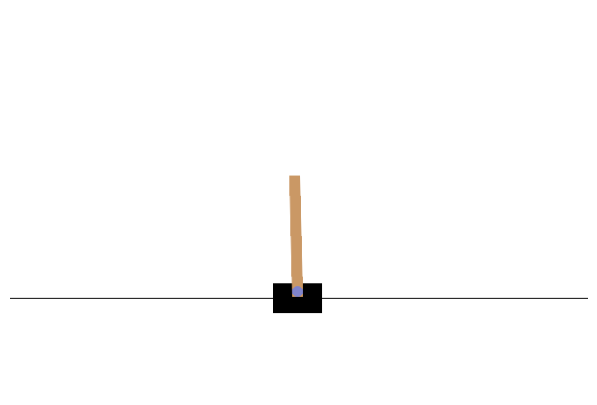

In [ ]:
import matplotlib.pyplot as plt
from IPython import display
from stable_baselines3.common.vec_env import VecEnv

# Retrieve the vectorized wrapper environment
vec_env: VecEnv = model_a2c.get_env()
obs = vec_env.reset()

# Configure a high-quality figure for rendering inline steps
fig, ax = plt.subplots(figsize=(8, 5), dpi=100)
img = ax.imshow(vec_env.render(mode='rgb_array'))
ax.axis('off')

# Execute a rollout and dynamically refresh the figure canvas
for step in range(150):
    action, _states = model_a2c.predict(obs, deterministic=True)
    obs, rewards, dones, info = vec_env.step(action)

    # Capture current environment frame
    frame = vec_env.render(mode='rgb_array')
    img.set_data(frame)

    # Re-draw step illustration
    display.display(plt.gcf())
    display.clear_output(wait=True)

    if dones[0]:
        obs = vec_env.reset()

plt.close(fig)

### Proximal Policy Optimization (PPO)

In [ ]:
# Instantiate a stable-baselines3 PPO policy model
model_ppo = PPO('MlpPolicy', stable_env, verbose=1)

# Train the PPO agent over the course of 10,000 environment steps
model_ppo.learn(total_timesteps=10000)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 44.6        |
|    ep_rew_mean          | 44.6        |
| time/                   |             |
|    fps                  | 895         |
|    iterations           | 4           |
|    time_elapsed         | 9           |
|    total_timesteps      | 8192        |
| train/                  |             |
|    approx_kl            | 0.009849995 |
|    clip_fraction        | 0.107       |
|    clip_range           | 0.2         |
|    entropy_loss         | -0.636      |
|    explained_variance   | 0.278       |
|    learning_rate        | 0.0003      |
|    loss                 | 22.9        |
|    n_updates            | 30          |
|    policy_gradient_loss | -0.021      |
|    value_loss           | 47.3        |
-----------------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 58.5  

#### Explaination of logger output

rollout/  
- ep_len_mean - mean episode length
- ep_rew_mean - mean episodic training reward

time/
- fps - number of frames per seconds
- time_elapsed - time in seconds since the beginning of training
- total_timesteps - total number of timesteps (steps in the environments)

train/
- approx_kl - mean KL divergence between old and new policy (for PPO), estimation of how much changes happened in the update
- entropy_loss - mean value of entropy loss
- explained_variance - fraction of the return variance explained by the value function
- learning_rate - current learning rate value
- loss - current total loss value
- policy_gradient_loss - current value of the policy gradient loss
- value-loss - current value for the value function loss for on-policy algorithms

#### Test the Trained Agent

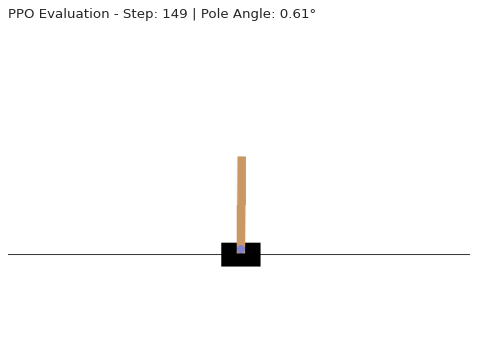

In [ ]:
import math
from typing import Tuple
from IPython import display
import matplotlib.pyplot as plt

# Evaluate the trained PPO policy over 10 independent trials
eval_results_ppo: Tuple[float, float] = evaluate_policy(model_ppo, stable_env, n_eval_episodes=10)
mean_reward_ppo, std_reward_ppo = eval_results_ppo
print(f"PPO Evaluation Mean Reward: {mean_reward_ppo:.2f} +/- {std_reward_ppo:.2f}")

# Set up render visualizations using the PPO agent model
vec_env_ppo = model_ppo.get_env()
obs = vec_env_ppo.reset()

for i in range(150):
    action, _states = model_ppo.predict(obs, deterministic=True)
    obs, rewards, dones, info = vec_env_ppo.step(action)

    # Render current state transition details
    state_img = vec_env_ppo.render(mode='rgb_array')
    fig = plt.figure(figsize=(10, 5), dpi=80)
    plt.imshow(state_img)
    plt.title(f'PPO Evaluation - Step: {i} | Pole Angle: {obs[0][2] * 180 / math.pi:.2f}°', loc='left', fontsize=12)
    plt.axis('off')

    display.display(fig)
    display.clear_output(wait=True)
    plt.close(fig)

### Contextual Multi-armed Bandit

In a contextual bandit scenario, an agent repeatedly observes a state vector (context), chooses an action from an available discrete set, and experiences a numerical reward (or loss). This section demonstrates using Vowpal Wabbit's online exploration algorithms to learn optimal actions.

In [ ]:
# Cleanly install vowpalwabbit package
!pip install vowpalwabbit > /dev/null 2>&1

In [ ]:
import vowpalwabbit

#### Problem parameters

In [ ]:
from typing import List

# Define contextual parameters for the truck delivery configuration task
shared_contexts: List[str] = ['city', 'interstate']
num_actions: int = 3

# Configure custom multi-class categorical option sets
size_options: List[str] = ['small', 'medium', 'large']
engine_types: List[str] = ['petrol', 'diesel', 'electric']
tire_types: List[str] = ['all_season', 'snow', 'performance', 'all_terrain']

#### Reward function

In [ ]:
def reward_function(shared_context: str, size_index: int, engine_index: int, tire_index: int) -> float:
    """
    Computes a synthetic numerical reward based on the selected options and context.

    Parameters:
        shared_context (str): Environment context ('city' or 'interstate').
        size_index (int): Selected truck size option.
        engine_index (int): Selected engine option.
        tire_index (int): Selected tire option.

    Returns:
        float: Calculated reward with added random normal noise.
    """
    size_value: List[float] = [0.8, 1.0, 0.9]
    engine_value: List[float] = [0.7, 0.9, 1.0]
    tire_value: List[float] = [0.9, 0.8, 1.0, 0.95]

    reward: float = size_value[size_index] * engine_value[engine_index] * tire_value[tire_index]

    # Add standard Gaussian noise to the reward function
    noise_scale: float = 0.05
    noise_value: float = float(np.random.normal(0.0, noise_scale))
    reward += noise_value

    return reward

#### Generate combinations

In [ ]:
from typing import Tuple, List

def generate_combinations(
    shared_context: str,
    size_options: List[str],
    engine_types: List[str],
    tire_types: List[str]
) -> Tuple[List[str], List[Tuple[int, int, int]]]:
    """
    Generates action combination vectors formatted for Vowpal Wabbit ADF format.

    Returns:
        Tuple[List[str], List[Tuple[int, int, int]]]: Vowpal Wabbit example strings and matching options.
    """
    descriptions: List[Tuple[int, int, int]] = []
    examples: List[str] = [f'shared |User={shared_context}']

    for size_index, size in enumerate(size_options):
        for engine_index, engine in enumerate(engine_types):
            for tire_index, tire in enumerate(tire_types):
                # Use standard '|' namespace separator for features
                examples.append(f'| truck size={size} engine={engine} tire={tire}')
                descriptions.append((size_index, engine_index, tire_index))

    return examples, descriptions

#### Sample delivery trucks using PMF

In [ ]:
import torch
from typing import Tuple

def sample_truck_pmf(pmf: List[float]) -> Tuple[int, float]:
    """
    Samples an action index based on a calculated probability mass function (PMF).

    Parameters:
        pmf (List[float]): Categorical probability distribution values.

    Returns:
        Tuple[int, float]: Selected action index and its matching selection probability.
    """
    pmf_tensor: torch.Tensor = torch.tensor(pmf)
    index: int = int(torch.multinomial(pmf_tensor, 1).item())
    chosen_prob: float = float(pmf[index])

    return index, chosen_prob

#### Contextual bandit
Explore First - Epsilon Greedy - Bagging Explorer - Online Cover - Softmax Explorer

In [ ]:
# Initialize the Vowpal Wabbit contextual bandit ADF learning workspace
cb_vw = vowpalwabbit.Workspace(
    "--cb_explore_adf --epsilon 0.2 --interactions AA AU AAU -l 0.05 --power_t 0",
    quiet=True
)

#### Training Loop

In [ ]:
import random

# Reinitialize Vowpal Wabbit workspace to ensure training starts fresh
cb_vw = vowpalwabbit.Workspace(
    "--cb_explore_adf --epsilon 0.2 --interactions AA AU AAU -l 0.05 --power_t 0",
    quiet=True
)

num_iterations: int = 2000
cb_rewards: List[float] = []

with tqdm(total=num_iterations, desc='Training Contextual Bandit') as pbar:
    for _ in range(num_iterations):
        shared_context: str = random.choice(shared_contexts)
        examples, indices = generate_combinations(
            shared_context, size_options, engine_types, tire_types
        )

        # Predict probability distribution over action representations
        cb_predictions = cb_vw.predict(examples)
        chosen_index, prob = sample_truck_pmf(cb_predictions)

        # Retrieve corresponding option parameters and calculate target reward
        size_index, engine_index, tire_index = indices[chosen_index]
        reward: float = reward_function(shared_context, size_index, engine_index, tire_index)
        cb_rewards.append(reward)

        # Format cost-sensitive specification for the selected action line:
        # action_index:cost:probability | features
        # Note: Cost in Vowpal Wabbit is negative reward
        examples[chosen_index + 1] = f'{chosen_index + 1}:{-1.0 * reward}:{prob} {examples[chosen_index + 1]}'

        cb_vw.learn(examples)
        pbar.update(1)

cb_vw.finish()

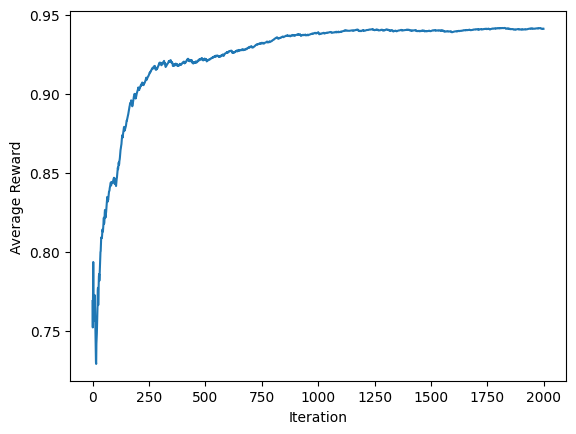

In [ ]:
''' Plot the average reward '''
plt.figure(figsize=(10, 5), dpi=100)
plt.plot(pd.Series(cb_rewards).expanding().mean(), color='forestgreen', linewidth=2)
plt.title('Contextual Multi-Armed Bandit Performance', fontsize=14)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Cumulative Average Reward', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

#### Perform predictions

In [ ]:
def test_model(
    shared_context: str,
    size_options: List[str],
    engine_types: List[str],
    tire_types: List[str]
) -> None:
    """
    Performs a deterministic evaluation test utilizing the trained Vowpal Wabbit model.
    """
    examples, indices = generate_combinations(shared_context, size_options, engine_types, tire_types)
    cb_predictions = cb_vw.predict(examples)
    chosen_index, prob = sample_truck_pmf(cb_predictions)

    chosen_action: str = examples[chosen_index]
    size_index, engine_index, tire_index = indices[chosen_index]

    expected_reward: float = reward_function(shared_context, size_index, engine_index, tire_index)
    print(f"Context: {shared_context}")
    print(f"Chosen Action Features: {chosen_action}")
    print(f"Expected Reward: {expected_reward:.4f}")

test_model('city', size_options, engine_types, tire_types)

Chosen action:  | truck size=medium engine=electric tire=snow
Expected reward:  1.1095856441696137
